# Лабораторная работа №2. Классификация: выживание на Титанике

**Задача:** по данным пассажира предсказать, выжил он (`Survived = 1`) или нет (`Survived = 0`). Это бинарная классификация.

**Метрики:** основная — F1-score для класса `Survived = 1` (порог F1 > 0.70), дополнительно Accuracy, Precision, Recall и confusion matrix.

**План:**
1. Первичный анализ данных (EDA) и выводы.
2. Подготовка признаков и обоснование обработки.
3. Разбиение на train/test.
4. Метрики и смысл ошибок FP/FN.
5. Dummy baseline.
6. Модели: Decision Tree, Random Forest, Gradient Boosting, SVM, KNN.
7. Честное сравнение моделей.
8. Анализ важности признаков.
9. Анализ ошибок лучшей модели и проверка на «запоминание» пассажиров.

In [ ]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.simplefilter("ignore")
sns.set(style="whitegrid")
pd.set_option("display.precision", 3)

RANDOM_STATE = 42 
np.random.seed(RANDOM_STATE)

## 1. Первичный анализ данных

Датасет [Titanic Dataset (Kaggle)](https://www.kaggle.com/datasets/yasserh/titanic-dataset) — 891 пассажир. Файл `Titanic-Dataset.csv` нужно положить в папку `data/` рядом с ноутбуком.

Признаки:
* `PassengerId` — порядковый номер записи;
* `Pclass` — класс билета (1 — первый, 3 — третий);
* `Name` — имя, включая обращение (Mr, Mrs, Miss, Master…);
* `Sex`, `Age` — пол и возраст;
* `SibSp` — число братьев/сестёр и супругов на борту, `Parch` — родителей и детей;
* `Ticket` — номер билета, `Fare` — стоимость билета;
* `Cabin` — номер каюты, `Embarked` — порт посадки (C — Шербур, Q — Квинстаун, S — Саутгемптон).

In [2]:
DATA_PATH = os.path.join("data", "Titanic-Dataset.csv")
df = pd.read_csv(DATA_PATH)
TARGET = "Survived"
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.050,NaN,S


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
overview = pd.DataFrame({
    "тип": df.dtypes.astype(str),
    "уникальных": df.nunique(),
    "пропусков": df.isna().sum(),
    "доля пропусков": df.isna().mean().round(3),
})
overview

,тип,уникальных,пропусков,доля пропусков
PassengerId,int64,891,0,0.000
Survived,int64,2,0,0.000
Pclass,int64,3,0,0.000
Name,str,891,0,0.000
Sex,str,2,0,0.000
Age,float64,88,177,0.199
SibSp,int64,7,0,0.000
Parch,int64,7,0,0.000
Ticket,str,681,0,0.000
Fare,float64,248,0,0.000


In [5]:
print("Полных дубликатов строк:", df.duplicated().sum())
print("Дубликатов без учёта PassengerId:", df.drop(columns="PassengerId").duplicated().sum())
df.describe().T

Полных дубликатов строк: 0
Дубликатов без учёта PassengerId: 0


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000,257.354,1.00,223.500,446.000,668.5,891.000
Survived,891.0,0.384,0.487,0.00,0.000,0.000,1.0,1.000
Pclass,891.0,2.309,0.836,1.00,2.000,3.000,3.0,3.000
Age,714.0,29.699,14.526,0.42,20.125,28.000,38.0,80.000
SibSp,891.0,0.523,1.103,0.00,0.000,0.000,1.0,8.000
Parch,891.0,0.382,0.806,0.00,0.000,0.000,0.0,6.000
Fare,891.0,32.204,49.693,0.00,7.910,14.454,31.0,512.329


**Выводы по структуре данных.**
* Дубликатов нет, даже если не учитывать `PassengerId`.
* **Пропуски:** `Age` — 177 (≈ 20%), `Cabin` — 687 (≈ 77%), `Embarked` — 2. Их придётся обрабатывать, причём по-разному: возраст важен и пропущен умеренно, каюта пропущена почти всегда, у порта посадки пропусков единицы.
* **Признаки, требующие отдельной обработки:** категориальные `Sex`, `Embarked`, `Pclass` (порядковый, но всего 3 значения); текстовые `Name`, `Ticket`, `Cabin`.
* **Признаки-идентификаторы, которые нельзя давать модели как есть:**
  * `PassengerId` — просто номер строки, уникален для каждого пассажира и не несёт информации о выживании. Модель может найти в нём случайные закономерности.
  * `Name` — уникален (891 значение на 891 пассажира). Как категория он позволяет модели запомнить конкретного человека, а на новых пассажирах бесполезен.
  * `Ticket` — 681 уникальное значение, большинство билетов встречается один раз. Это почти идентификатор.
  * `Cabin` — 147 значений при 77% пропусков; конкретный номер каюты тоже почти уникален.

  Такие признаки дают «бессмысленное запоминание»: дерево легко разделит обучающую выборку по именам и билетам, но это не обобщается. Из них можно аккуратно извлечь **общие** закономерности: обращение из имени (`Title`), факт наличия каюты (`HasCabin`), — но не сами значения.
* **Утечка целевой переменной.** В полной версии датасета есть столбцы `Boat` (номер шлюпки) и `Body` (номер найденного тела) — они известны только после катастрофы и фактически содержат ответ. В этой версии их нет. Но утечку можно создать и самому: например, если посчитать «долю выживших среди пассажиров с тем же билетом» по всему датасету, то в признак попадёт ответ для самого пассажира и для тестовых объектов. Мы такие признаки не строим.

### 1.1. Целевая переменная

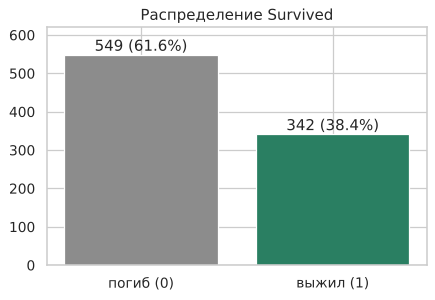

In [6]:
counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["погиб (0)", "выжил (1)"], counts.values, color=["#8C8C8C", "#2A7F62"])
for i, c in enumerate(counts.values):
    ax.text(i, c + 10, f"{c} ({c / len(df):.1%})", ha="center")
ax.set_title("Распределение Survived")
ax.set_ylim(0, 620)
plt.tight_layout()

**Вывод.** Классы несбалансированы умеренно: выжили 38.4%, погибли 61.6%. Отсюда:
* модель, которая всегда отвечает «погиб», получит Accuracy ≈ 0.62, ничего не зная о пассажирах. Поэтому одна Accuracy плохо показывает качество, и основная метрика — F1 для класса «выжил»;
* разбивать данные нужно **со стратификацией**, чтобы доля выживших в train и test совпадала.

### 1.2. Связь признаков с выживанием

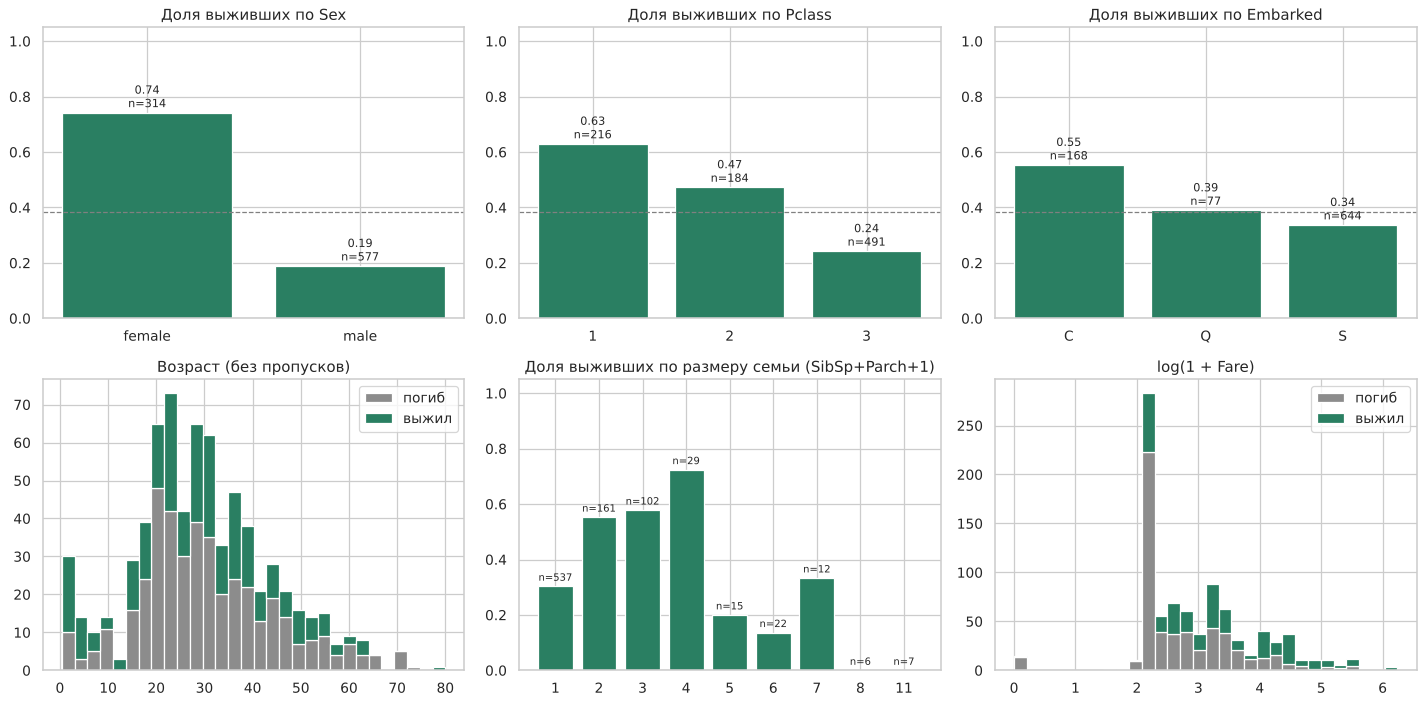

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes[0], ["Sex", "Pclass", "Embarked"]):
    s = df.groupby(col)[TARGET].agg(["mean", "count"])
    ax.bar(s.index.astype(str), s["mean"], color="#2A7F62")
    for i, (m, c) in enumerate(zip(s["mean"], s["count"])):
        ax.text(i, m + 0.02, f"{m:.2f}\nn={c}", ha="center", fontsize=9)
    ax.set_ylim(0, 1.05)
    ax.set_title(f"Доля выживших по {col}")
    ax.axhline(df[TARGET].mean(), color="gray", ls="--", lw=1)

ages = df.dropna(subset=["Age"])
axes[1, 0].hist([ages.loc[ages[TARGET] == 0, "Age"], ages.loc[ages[TARGET] == 1, "Age"]],
                bins=30, stacked=True, color=["#8C8C8C", "#2A7F62"], label=["погиб", "выжил"])
axes[1, 0].legend()
axes[1, 0].set_title("Возраст (без пропусков)")

fam = (df.SibSp + df.Parch + 1)
s = df.groupby(fam)[TARGET].agg(["mean", "count"])
axes[1, 1].bar(s.index.astype(str), s["mean"], color="#2A7F62")
for i, (m, c) in enumerate(zip(s["mean"], s["count"])):
    axes[1, 1].text(i, m + 0.02, f"n={c}", ha="center", fontsize=8)
axes[1, 1].set_title("Доля выживших по размеру семьи (SibSp+Parch+1)")
axes[1, 1].set_ylim(0, 1.05)

axes[1, 2].hist([np.log1p(df.loc[df[TARGET] == 0, "Fare"]), np.log1p(df.loc[df[TARGET] == 1, "Fare"])],
                bins=30, stacked=True, color=["#8C8C8C", "#2A7F62"], label=["погиб", "выжил"])
axes[1, 2].set_title("log(1 + Fare)")
axes[1, 2].legend()
plt.tight_layout()

In [8]:
print("Доля выживших по полу и классу:")
print(df.pivot_table(index="Sex", columns="Pclass", values=TARGET, aggfunc="mean").round(3))
print("\nЧисло пассажиров:")
print(df.pivot_table(index="Sex", columns="Pclass", values=TARGET, aggfunc="count"))
print("\nДоля выживших, если возраст известен / пропущен:")
print(df.groupby(df.Age.isna().map({False: "известен", True: "пропущен"}))[TARGET].mean().round(3))
print("\nДоля выживших, если каюта известна / пропущена:")
print(df.groupby(df.Cabin.isna().map({False: "известна", True: "пропущена"}))[TARGET].mean().round(3))
print("\nДети до 10 лет:", df.loc[df.Age < 10, TARGET].mean().round(3), " остальные с известным возрастом:", df.loc[df.Age >= 10, TARGET].mean().round(3))

Доля выживших по полу и классу:
Pclass      1      2      3
Sex                        
female  0.968  0.921  0.500
male    0.369  0.157  0.135

Число пассажиров:
Pclass    1    2    3
Sex                  
female   94   76  144
male    122  108  347

Доля выживших, если возраст известен / пропущен:
Age
известен    0.406
пропущен    0.294
Name: Survived, dtype: float64

Доля выживших, если каюта известна / пропущена:
Cabin
известна     0.667
пропущена    0.300
Name: Survived, dtype: float64

Дети до 10 лет: 0.613  остальные с известным возрастом: 0.387


In [9]:
title = df["Name"].str.extract(r",\s*([^\.]+)\.")[0]
print("Обращения в именах:\n", title.value_counts().to_string())
df.assign(Title=title).groupby("Title")[TARGET].agg(["mean", "count"]).sort_values("count", ascending=False).head(6)

Обращения в именах:
 0
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1


,mean,count
Title,,
Mr,0.157,517
Miss,0.698,182
Mrs,0.792,125
Master,0.575,40
Dr,0.429,7
Rev,0.000,6


**Выводы по связи признаков с выживанием.**
* **Пол — самый сильный фактор.** Выжили ≈ 74% женщин и ≈ 19% мужчин. Это прямое следствие правила «женщины и дети — первыми» при посадке в шлюпки. Признак обязательно должен быть в модели; уже одно правило «женщина → выжила» даёт сильный результат.
* **Класс билета** — второй по силе фактор: в 1-м классе выжили ≈ 63%, в 3-м ≈ 24%. Каюты 1-го класса располагались выше и ближе к шлюпкам, а пассажиры 3-го класса дольше добирались до палубы. Класс **взаимодействует** с полом: женщины 1–2 классов выжили почти все (97% и 92%), а женщины 3-го класса — лишь наполовину. Такие взаимодействия хорошо ловят деревья.
* **Возраст**: дети до 10 лет выживали заметно чаще (≈ 61%), в остальном возраст влияет слабо. Пропуск возраста сам несёт информацию: у пассажиров без возраста доля выживших ниже (≈ 29% против ≈ 41%), они чаще из 3-го класса. Поэтому при заполнении пропусков стоит сохранить флаг «возраст был пропущен».
* **Обращение (`Title`)** объединяет пол, возраст и статус: `Master` — мальчики (выжили ≈ 57%, в отличие от взрослых `Mr` ≈ 16%), `Miss`/`Mrs` — женщины. Это полезный признак, который можно извлечь из имени без запоминания конкретных людей.
* **Размер семьи** влияет нелинейно: одиночки выживали реже (≈ 30%), семьи из 2–4 человек — чаще (55–72%), а большие семьи (5+) — почти никогда. Линейная модель такую «горку» не поймает, деревья поймают.
* **`Fare`** сильно скошен вправо (до 512), высокая цена связана с выживанием, но во многом через класс. **`Cabin`**: если каюта известна, выжили ≈ 67%, иначе ≈ 30%. Это отражает класс (каюты в основном записаны у 1-го класса) и то, что о выживших просто сохранилось больше сведений.
* **`Embarked`**: из Шербура (C) выжили ≈ 55%, но там больше пассажиров 1-го класса, так что это, скорее всего, косвенный эффект класса, а не самого порта.

## 2. Подготовка признаков

**Шаг 1. Построчные преобразования (до разбиения).** Эти признаки вычисляются по одной строке, без статистик по выборке, поэтому их можно считать до разбиения — утечки нет:
* `Title` — обращение из имени. Редкие обращения (Dr, Rev, Col и т. п., всего 23 человека) объединяем в `Rare`; `Mlle`/`Ms` → `Miss`, `Mme` → `Mrs` (это французские и нейтральные формы тех же обращений).
* `FamilySize = SibSp + Parch + 1` — размер семьи на борту.
* `HasCabin` — известен ли номер каюты (1/0). Сам номер не используем.

**Удаляем** `PassengerId`, `Name`, `Ticket`, `Cabin` — это идентификаторы или почти идентификаторы (см. EDA).

**Шаг 2. Преобразования с параметрами (только на train, внутри `Pipeline`):**
* `Age`, `Fare` — пропуски заполняем **медианой** обучающей выборки (медиана устойчива к скошенному распределению и выбросам) и добавляем флаг `missingindicator_Age`, т.к. сам пропуск связан с выживанием.
* `Embarked` — 2 пропуска заполняем **самым частым** значением train (`S`); на результат это почти не влияет.
* Категориальные `Sex`, `Embarked`, `Title`, `Pclass` — **one-hot encoding**. У этих признаков нет естественного числового порядка (кроме `Pclass`, но и для него one-hot безопаснее для SVM и KNN: расстояние между 1-м и 3-м классом не обязано быть «вдвое больше», чем между 1-м и 2-м). `handle_unknown="ignore"` — на случай нового значения в тесте.
* **Масштабирование** (`StandardScaler`) числовых признаков — только для SVM и KNN (обсуждение ниже).

Все шаги второго типа обёрнуты в `Pipeline`, поэтому медианы, частые значения и параметры масштабирования вычисляются **только на обучающей части** (и на каждом фолде кросс-валидации — только на его train-части). Тестовая выборка их никак не влияет.

In [10]:
MAIN_TITLES = ["Mr", "Mrs", "Miss", "Master"]
TITLE_MAP = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}


def add_features(data):
    """Построчные признаки: не используют статистик по выборке, утечки нет."""
    d = data.copy()
    t = d["Name"].str.extract(r",\s*([^\.]+)\.")[0].replace(TITLE_MAP)
    d["Title"] = t.where(t.isin(MAIN_TITLES), "Rare")
    d["FamilySize"] = d["SibSp"] + d["Parch"] + 1
    d["HasCabin"] = d["Cabin"].notna().astype(int)
    return d


NUM_FEATURES = ["Age", "Fare", "SibSp", "Parch", "FamilySize"]
CAT_FEATURES = ["Pclass", "Sex", "Embarked", "Title"]
BIN_FEATURES = ["HasCabin"]
FEATURES = NUM_FEATURES + CAT_FEATURES + BIN_FEATURES
DROPPED = ["PassengerId", "Name", "Ticket", "Cabin"]

data = add_features(df)
X = data[FEATURES]
y = data[TARGET]
print("Признаки модели:", FEATURES)
print("Удалены:", DROPPED)
X.head()

Признаки модели: ['Age', 'Fare', 'SibSp', 'Parch', 'FamilySize', 'Pclass', 'Sex', 'Embarked', 'Title', 'HasCabin']
Удалены: ['PassengerId', 'Name', 'Ticket', 'Cabin']


,Age,Fare,SibSp,Parch,FamilySize,Pclass,Sex,Embarked,Title,HasCabin
0,22.0,7.250,1,0,2,3,male,S,Mr,0
1,38.0,71.283,1,0,2,1,female,C,Mrs,1
2,26.0,7.925,0,0,1,3,female,S,Miss,0
3,35.0,53.100,1,0,2,1,female,S,Mrs,1
4,35.0,8.050,0,0,1,3,male,S,Mr,0


In [11]:
def make_preprocessor(scale):
    num_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUM_FEATURES),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT_FEATURES),
        ("bin", "passthrough", BIN_FEATURES),
    ], verbose_feature_names_out=False)


def make_pipeline(model, scale=False):
    return Pipeline([("prep", make_preprocessor(scale)), ("model", model)])

**Для каких алгоритмов важно масштабирование.**
* **Деревья (Decision Tree, Random Forest, Gradient Boosting)** — не важно. Дерево задаёт вопросы вида «`Fare` ≤ 15.5?»; если умножить `Fare` на 100, порог просто станет 1550, а разбиение — тем же. Решения деревьев не зависят от монотонных преобразований признаков.
* **SVM с RBF-ядром** — важно. Ядро $K(x, x') = \exp(-\gamma \lVert x - x' \rVert^2)$ основано на расстоянии между объектами. Без масштабирования `Fare` (0…512) полностью задавит в расстоянии `Sex` (0/1), и модель фактически будет смотреть только на цену билета.
* **KNN** — особенно важно: весь алгоритм — это «найти ближайших соседей по евклидову расстоянию». Признак с большим разбросом определяет, кто «ближайший». Ниже это проверено экспериментом.

## 3. Разбиение на train и test

* **80% / 20%** (712 / 179 пассажиров). Данных мало, поэтому большую часть оставляем на обучение; 179 объектов (≈ 69 выживших) достаточно для финальной оценки, но F1 на таком тесте всё равно заметно «шумит» — разница в 1–2 угаданных пассажира меняет F1 на 0.01–0.02.
* **`stratify=y`** — доля выживших в train и test одинакова.
* **`random_state=42`** — разбиение воспроизводимо; все модели обучаются и оцениваются на нём.
* Гиперпараметры выбираем **кросс-валидацией на train** (`StratifiedKFold`, 5 фолдов), тест используется один раз в конце. Если подбирать модель по тесту, итоговая оценка станет завышенной: мы подгоним решение под 179 конкретных пассажиров.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"train: {len(X_train)},  test: {len(X_test)}")
pd.DataFrame({"доля выживших": [y_train.mean(), y_test.mean()],
              "выживших, шт.": [y_train.sum(), y_test.sum()]}, index=["train", "test"])

train: 712,  test: 179


,доля выживших,"выживших, шт."
train,0.383,273
test,0.385,69


In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
# для итогового сравнения моделей — повторённая CV (5 фолдов × 5 повторов): меньше зависит от одного разбиения
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

results, cv_table, fitted, test_pred = {}, {}, {}, {}


def metrics(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred)}


def evaluate(name, model, show=True):
    """Обучает модель на train, считает метрики на train/test, CV-оценку на train и рисует confusion matrix."""
    cvr = cross_validate(model, X_train, y_train, cv=cv_rep, n_jobs=-1,
                         scoring=["f1", "accuracy", "precision", "recall"])
    cv_table[name] = {"CV F1": cvr["test_f1"].mean(), "CV F1 std": cvr["test_f1"].std(),
                      "CV Accuracy": cvr["test_accuracy"].mean()}
    model.fit(X_train, y_train)
    fitted[name] = model
    pred = model.predict(X_test)
    test_pred[name] = pred
    results[name] = metrics(y_test, pred)
    tr = metrics(y_train, model.predict(X_train))
    if show:
        tab = pd.DataFrame({"train": tr, "test": results[name]}).T
        tab["CV F1 (train, 5×5)"] = [cv_table[name]["CV F1"], np.nan]
        print(name)
        display(tab.round(3))
        fig, ax = plt.subplots(figsize=(4, 3.4))
        ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                               display_labels=["погиб", "выжил"]).plot(ax=ax, cmap="Greens", colorbar=False)
        ax.set_title(f"{name}: confusion matrix (test)")
        ax.grid(False)
        ax.set_xlabel("предсказано")
        ax.set_ylabel("на самом деле")
        plt.tight_layout()
    return model


def tune(model, grid, scale=False):
    """Подбор гиперпараметров кросс-валидацией только на train."""
    gs = GridSearchCV(make_pipeline(model, scale), {f"model__{k}": v for k, v in grid.items()},
                      cv=cv, scoring="f1", n_jobs=-1)
    gs.fit(X_train, y_train)
    res = pd.DataFrame(gs.cv_results_)
    cols = [c for c in res.columns if c.startswith("param_")]
    top = res.sort_values("rank_test_score")[cols + ["mean_test_score", "std_test_score"]].head(5)
    top.columns = [c.replace("param_model__", "") for c in top.columns]
    return gs.best_estimator_, {k.replace("model__", ""): v for k, v in gs.best_params_.items()}, top

## 4. Метрики

Обозначим «выжил» как положительный класс. Тогда:
* **TP** — выжил, и модель сказала «выжил»; **TN** — погиб, модель сказала «погиб»;
* **FP (ложная тревога)** — модель сказала «выжил», а пассажир погиб;
* **FN (пропуск)** — модель сказала «погиб», а пассажир выжил.

Метрики:
* **Accuracy** $= \frac{TP + TN}{N}$ — доля верных ответов. Проста, но при дисбалансе обманчива: «все погибли» даёт 0.62.
* **Precision** $= \frac{TP}{TP + FP}$ — из тех, кого модель назвала выжившими, какая доля действительно выжила. Низкая precision = много ложных «выжил».
* **Recall** $= \frac{TP}{TP + FN}$ — какую долю реально выживших модель нашла. Низкий recall = много пропущенных выживших.
* **F1** $= 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ — гармоническое среднее. Оно высокое, только если высоки **обе** метрики: модель не может «выиграть», просто называя всех выжившими (precision упадёт) или почти никого (recall упадёт).

**FP и FN в контексте задачи.** Если представить, что модель используется, например, для оценки риска или планирования спасательных работ, то **FN** — это человек, которого модель «похоронила», хотя он выжил (в реальной спасательной операции такую ошибку цена выше: человека перестанут искать). **FP** — модель считает человека спасённым, а он погиб (ложная надежда, неверная оценка числа жертв). В исторической задаче цена ошибок примерно одинакова, поэтому подходит F1, который учитывает обе. Важно другое: эти ошибки возникают **у разных групп**. Модель, опирающаяся на пол, будет давать FN на выживших мужчинах и FP на погибших женщинах (особенно 3-го класса), — это видно в анализе ошибок.

## 5. Baseline: всегда «погиб»

`DummyClassifier(strategy="most_frequent")` всегда предсказывает самый частый класс train, то есть 0.

Baseline (most frequent)


,Accuracy,Precision,Recall,F1,"CV F1 (train, 5×5)"
train,0.617,0.0,0.0,0.0,0.0
test,0.615,0.0,0.0,0.0,NaN


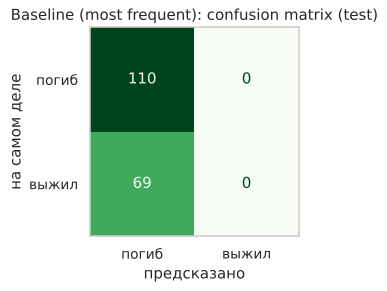

In [14]:
_ = evaluate("Baseline (most frequent)", Pipeline([("model", DummyClassifier(strategy="most_frequent"))]))

Baseline: Accuracy ≈ 0.615 (ровно доля погибших в тесте), но **Precision, Recall и F1 равны 0** — он не нашёл ни одного выжившего. Это наглядно показывает, почему Accuracy нельзя использовать как основную метрику: модель без единого полезного решения выглядит «правой в 62% случаев». Любая полезная модель должна иметь F1 > 0, а по условию — F1 > 0.70.

## 6. Модели
### 6.1. Decision Tree

Сначала посмотрим на дерево **без ограничений** — оно растёт, пока не разделит train идеально.

Decision Tree (без ограничений)
Глубина дерева: 22  листьев: 162


,Accuracy,Precision,Recall,F1,"CV F1 (train, 5×5)"
train,0.987,0.996,0.971,0.983,0.717
test,0.777,0.704,0.725,0.714,NaN


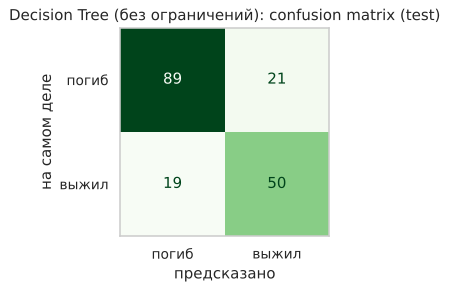

In [15]:
dt_full = evaluate("Decision Tree (без ограничений)", make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)))
print("Глубина дерева:", dt_full.named_steps["model"].get_depth(), " листьев:", dt_full.named_steps["model"].get_n_leaves())

Подберём глубину и минимальный размер листа по CV на train.

In [16]:
dt_best, dt_params, dt_top = tune(DecisionTreeClassifier(random_state=RANDOM_STATE),
                                  {"max_depth": [2, 3, 4, 5, 6, 8, 10, None], "min_samples_leaf": [1, 3, 5, 10, 20]})
print("Лучшие параметры:", dt_params)
dt_top

Лучшие параметры: {'max_depth': 3, 'min_samples_leaf': 1}


,max_depth,min_samples_leaf,mean_test_score,std_test_score
6,3,3,0.762,0.047
5,3,1,0.762,0.047
7,3,5,0.760,0.046
8,3,10,0.759,0.047
32,10,5,0.756,0.018


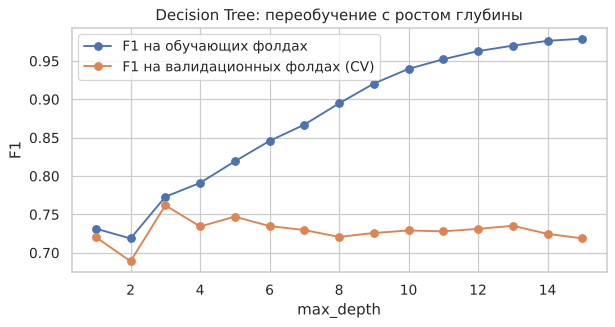

In [17]:
depths = list(range(1, 16))
tr_f1, cv_f1 = [], []
for d in depths:
    r = cross_validate(make_pipeline(DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)),
                       X_train, y_train, cv=cv, scoring="f1", return_train_score=True)
    tr_f1.append(r["train_score"].mean())
    cv_f1.append(r["test_score"].mean())
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(depths, tr_f1, "o-", label="F1 на обучающих фолдах")
ax.plot(depths, cv_f1, "o-", label="F1 на валидационных фолдах (CV)")
ax.set_xlabel("max_depth")
ax.set_ylabel("F1")
ax.set_title("Decision Tree: переобучение с ростом глубины")
ax.legend()
plt.tight_layout()

Decision Tree


,Accuracy,Precision,Recall,F1,"CV F1 (train, 5×5)"
train,0.831,0.812,0.729,0.768,0.758
test,0.832,0.820,0.725,0.769,NaN


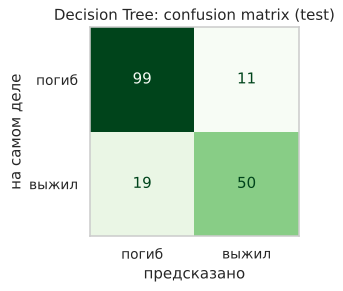

In [18]:
dt = evaluate("Decision Tree", make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE, **dt_params)))

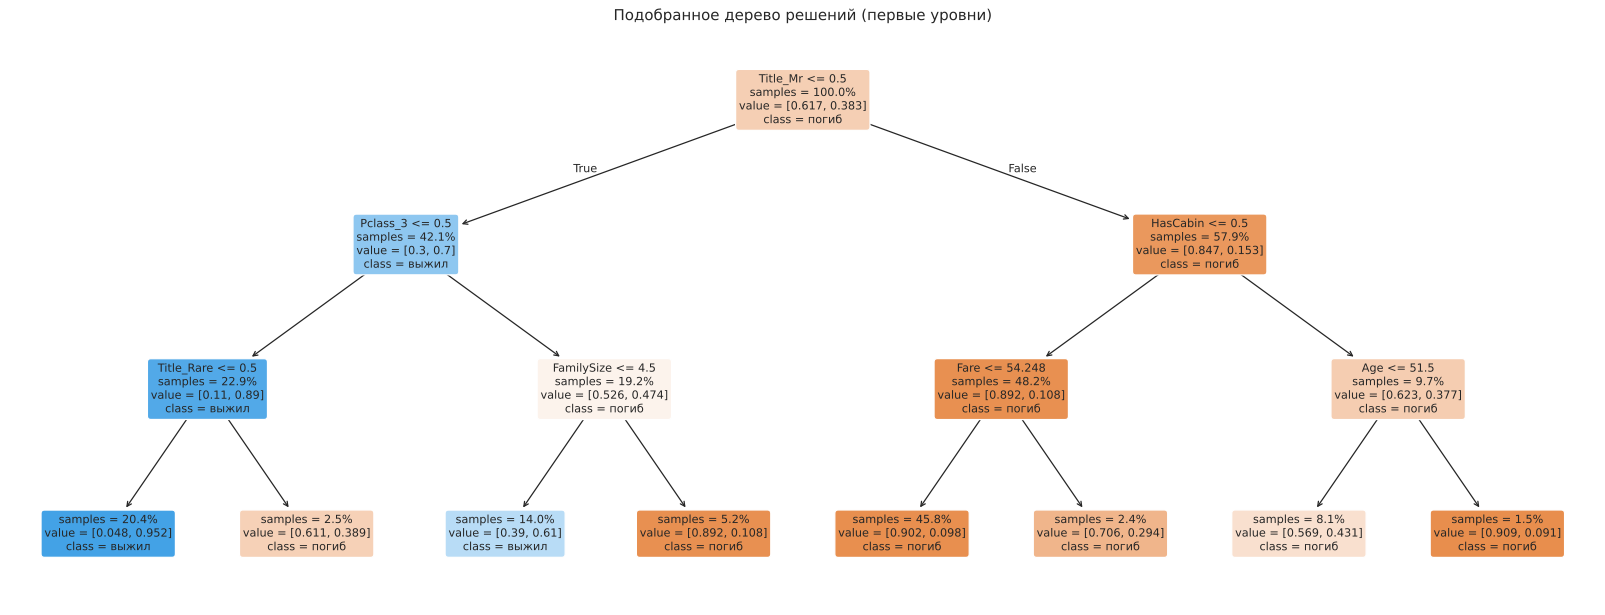

In [19]:
feat_names = list(dt.named_steps["prep"].get_feature_names_out())
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(dt.named_steps["model"], feature_names=feat_names, class_names=["погиб", "выжил"],
          filled=True, rounded=True, fontsize=9, impurity=False, proportion=True, ax=ax, max_depth=3)
ax.set_title("Подобранное дерево решений (первые уровни)")
plt.tight_layout()

**Выводы по Decision Tree.**
* **Дерево без ограничений сильно переобучено**: глубина 22, 162 листа, на train F1 = 0.98, а на CV — 0.72 и на тесте — 0.71. Оно запомнило отдельных пассажиров (листья по 1–2 человека с конкретной ценой билета и возрастом), а такие правила не переносятся на новых людей.
* График по глубине показывает классическую картину: F1 на обучающих фолдах растёт почти до 1, а на валидационных достигает максимума при глубине 3 и дальше не растёт. Разрыв между кривыми — это и есть переобучение.
* **Подобранное дерево** (глубина 3): F1 на train 0.77, на CV 0.76, на тесте 0.77 — значения почти совпадают, **признаков переобучения нет**. Ограничение глубины работает как регуляризация.
* Дерево читается как набор понятных правил, и они совпадают с EDA:
  * первый вопрос — «взрослый мужчина?» (`Title_Mr`). Все листья для взрослых мужчин предсказывают «погиб», даже для мужчин с каютой и дорогим билетом (там выживших 25 из 58 — меньше половины);
  * для женщин и мальчиков (`Master`) следующий вопрос — класс: не из 3-го класса → «выжил» (138 из 145 в листе);
  * в 3-м классе важен размер семьи: семьи до 4 человек → «выжил» (61 из 100), большие семьи → «погиб» (4 из 37 выжили).

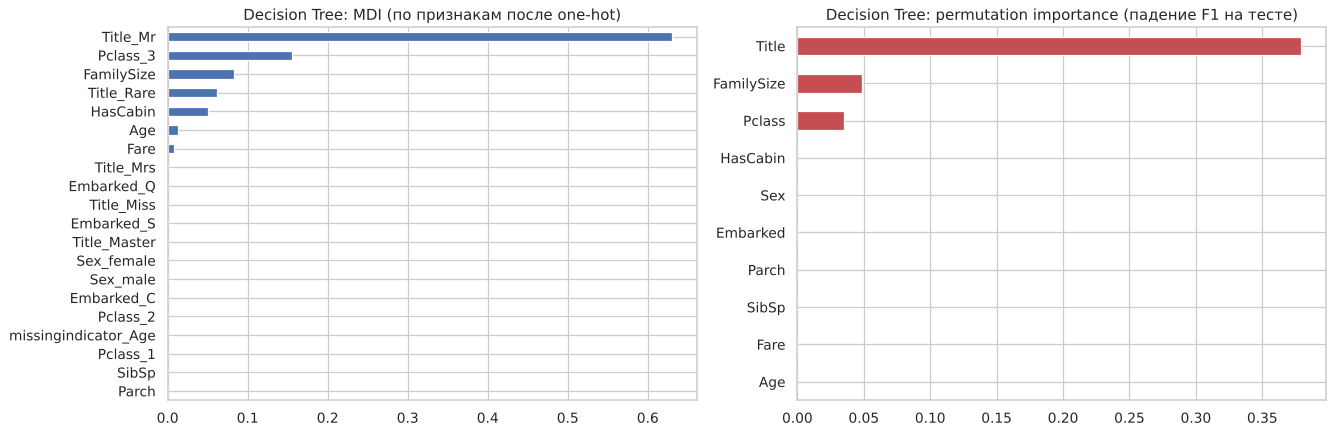

Title_Mr      0.630
Pclass_3      0.155
FamilySize    0.082
Title_Rare    0.061
HasCabin      0.050
Age           0.013
Fare          0.008
SibSp         0.000
dtype: float64

In [20]:
def get_importances(name):
    pipe = fitted[name]
    names = pipe.named_steps["prep"].get_feature_names_out()
    mdi = pd.Series(pipe.named_steps["model"].feature_importances_, index=names)
    # permutation importance считаем по ИСХОДНЫМ признакам (до one-hot), на тесте — только для анализа
    perm = permutation_importance(pipe, X_test, y_test, scoring="f1", n_repeats=30,
                                  random_state=RANDOM_STATE, n_jobs=-1)
    perm = pd.Series(perm.importances_mean, index=X_test.columns)
    return mdi, perm


def plot_importances(mdi, perm, title):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    mdi.sort_values().plot.barh(ax=axes[0], color="#4C72B0")
    axes[0].set_title(f"{title}: MDI (по признакам после one-hot)")
    perm.sort_values().plot.barh(ax=axes[1], color="#C44E52")
    axes[1].set_title(f"{title}: permutation importance (падение F1 на тесте)")
    plt.tight_layout()


importances = {}
importances["Decision Tree"] = get_importances("Decision Tree")
plot_importances(*importances["Decision Tree"], "Decision Tree")
importances["Decision Tree"][0].sort_values(ascending=False).head(8)

Есть два вида важности:
* **MDI** (`feature_importances_`) — насколько признак суммарно уменьшает неоднородность (Gini) в разбиениях. Считается по train, по признакам **после** one-hot (у `Title` — отдельно `Title_Mr`, `Title_Miss` и т. д.).
* **Permutation importance** — насколько упадёт F1 на тесте, если случайно перемешать значения **исходного** признака. Её считаем на тесте только для анализа, ничего по ней не выбираем.

**Выводы.** У дерева важность сосредоточена в нескольких признаках: `Title_Mr` (0.63, «взрослый мужчина или нет»), `Pclass_3` (0.16) и `FamilySize` (0.08). Многие признаки дерево вообще не использует (важность 0): у неглубокого дерева всего 7 разбиений. Важно: у `Sex` важность **нулевая**, хотя это самый информативный признак по EDA. Дело в том, что `Sex` и `Title_Mr` почти взаимозаменяемы: после разбиения по `Title_Mr` разбивать по полу уже не нужно. Нулевая важность здесь не значит «признак бесполезен» — она значит «модель обошлась другим, коррелированным признаком».

### 6.2. Random Forest

In [21]:
rf_best, rf_params, rf_top = tune(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
                                  {"max_depth": [4, 6, 8, None], "min_samples_leaf": [1, 3, 5], "max_features": ["sqrt", 0.5]})
print("Лучшие параметры:", rf_params)
rf_top

Лучшие параметры: {'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 3}


,max_depth,max_features,min_samples_leaf,mean_test_score,std_test_score
1,4,sqrt,3,0.773,0.038
2,4,sqrt,5,0.770,0.040
0,4,sqrt,1,0.770,0.038
15,8,0.5,1,0.768,0.022
16,8,0.5,3,0.767,0.036


Random Forest


,Accuracy,Precision,Recall,F1,"CV F1 (train, 5×5)"
train,0.837,0.815,0.744,0.778,0.77
test,0.799,0.770,0.681,0.723,NaN


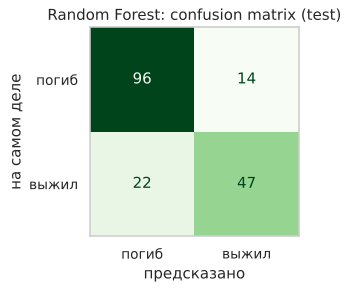

In [22]:
rf = evaluate("Random Forest", make_pipeline(RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, **rf_params)))

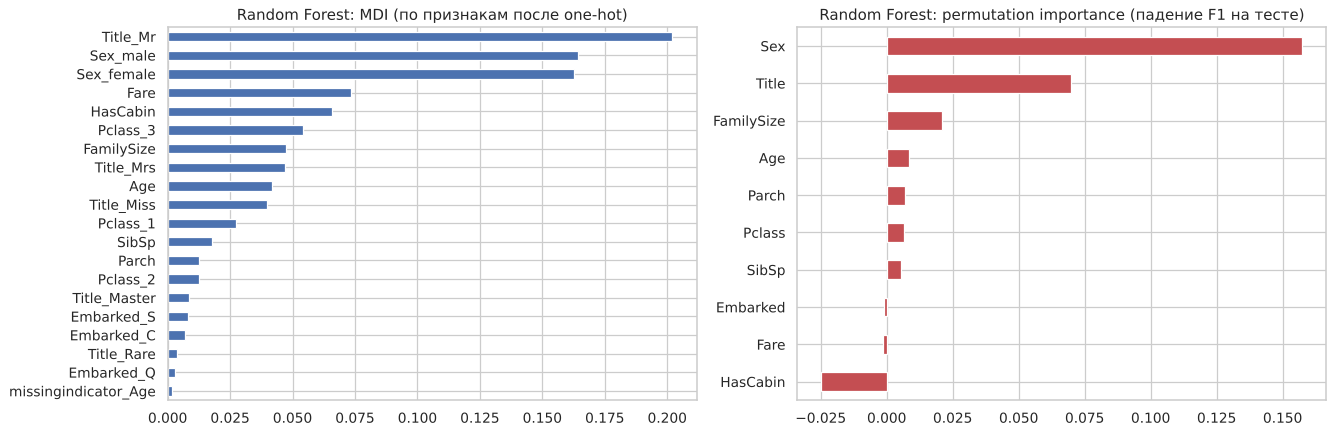

Title_Mr      0.202
Sex_male      0.164
Sex_female    0.163
Fare          0.073
HasCabin      0.066
Pclass_3      0.054
FamilySize    0.047
Title_Mrs     0.047
dtype: float64

In [23]:
importances["Random Forest"] = get_importances("Random Forest")
plot_importances(*importances["Random Forest"], "Random Forest")
importances["Random Forest"][0].sort_values(ascending=False).head(8)

**Выводы по Random Forest.**
* Лес — это усреднение сотен деревьев, обученных на бутстреп-выборках со случайным подмножеством признаков в каждом разбиении. Поэтому важность у него **распределена шире**, чем у одного дерева: деревья, которым «не достался» `Sex`, разбиваются по `Title_Mr` или `Title_Mrs`, и наоборот. В результате важность получают и `Sex`, и `Title`.
* Топ признаков совпадает с деревом и с EDA: `Title_Mr`, `Sex_male`/`Sex_female`, затем `Fare`, `HasCabin`, `Pclass_3`.
* У `Fare` и `HasCabin` MDI заметно выше, чем их реальная польза: по permutation importance перемешивание `Fare` почти не меняет F1 на тесте. Во-первых, MDI считается по train и известна смещением в пользу признаков с большим числом уникальных значений (их чаще выбирают для разбиений, в том числе подгоняясь под шум). Во-вторых, `Fare` и `HasCabin` дублируют информацию о классе: если перемешать один из них, модель опирается на `Pclass`.
* По метрикам лес на CV (0.770) лучше одного дерева (0.758), разрыв train/test небольшой. На тесте лес оказался хуже дерева (0.72 против 0.77) — это разброс оценки на маленьком тесте; подробнее в разделе 7.

### 6.3. Gradient Boosting

In [24]:
gb_best, gb_params, gb_top = tune(GradientBoostingClassifier(random_state=RANDOM_STATE),
                                  {"n_estimators": [100, 200, 400], "learning_rate": [0.03, 0.1],
                                   "max_depth": [2, 3, 4], "subsample": [1.0, 0.8]})
print("Лучшие параметры:", gb_params)
gb_top

Лучшие параметры: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 100, 'subsample': 1.0}


,learning_rate,max_depth,n_estimators,subsample,mean_test_score,std_test_score
0,0.03,2,100,1.0,0.776,0.042
15,0.03,4,200,0.8,0.773,0.018
14,0.03,4,200,1.0,0.769,0.027
22,0.10,2,400,1.0,0.767,0.010
17,0.03,4,400,0.8,0.766,0.029


Gradient Boosting


,Accuracy,Precision,Recall,F1,"CV F1 (train, 5×5)"
train,0.841,0.815,0.758,0.786,0.766
test,0.788,0.754,0.667,0.708,NaN


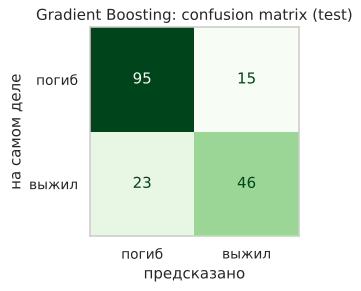

In [25]:
gb = evaluate("Gradient Boosting", make_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE, **gb_params)))

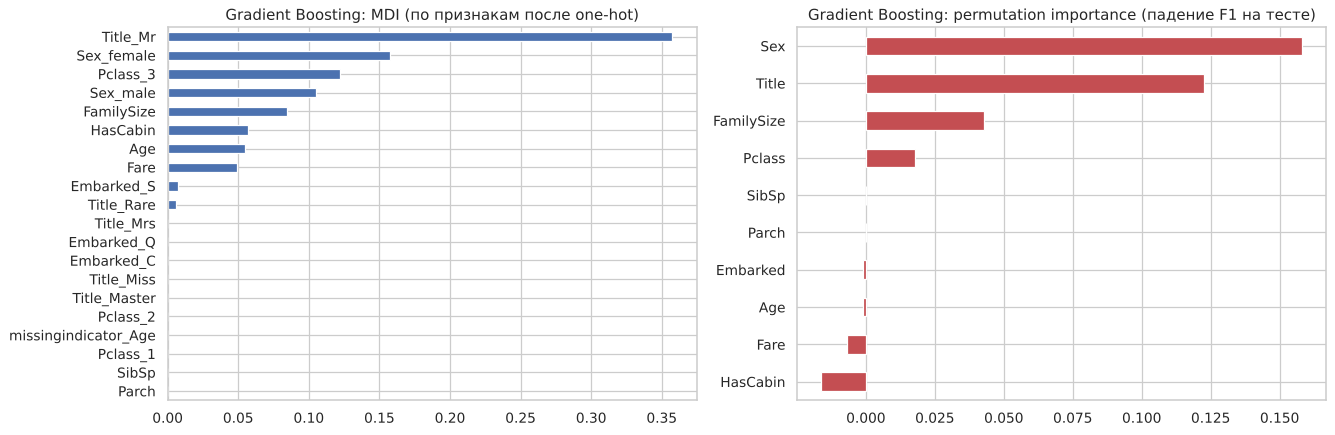

Title_Mr      0.357
Sex_female    0.158
Pclass_3      0.122
Sex_male      0.105
FamilySize    0.085
HasCabin      0.057
Age           0.055
Fare          0.049
dtype: float64

In [26]:
importances["Gradient Boosting"] = get_importances("Gradient Boosting")
plot_importances(*importances["Gradient Boosting"], "Gradient Boosting")
importances["Gradient Boosting"][0].sort_values(ascending=False).head(8)

**Выводы по Gradient Boosting.**
* Бустинг строит неглубокие деревья **последовательно**, каждое исправляет ошибки предыдущих. Первые деревья «съедают» самый сильный сигнал — `Title_Mr` (MDI 0.36 против 0.20 у леса). Последующие деревья уточняют исключения: класс (`Pclass_3` 0.12 против 0.05 у леса), размер семьи, возраст.
* **Сравнение с Random Forest.** Подобраны очень «осторожные» параметры: 100 деревьев глубины 2 с шагом 0.03. На CV бустинг (0.766) и лес (0.770) практически равны — разница меньше стандартного отклонения CV (≈ 0.04). На тесте бустинг 0.708, лес 0.723, — тоже в пределах шума. Небольшой датасет с сильным простым сигналом (пол + класс) не даёт бустингу преимущества: основную закономерность одинаково хорошо находят оба ансамбля, а дальнейшие уточнения быстро превращаются в подгонку под шум.
* Важность признаков у обоих ансамблей похожа по составу (обращение, пол, класс в топе), но бустинг сильнее концентрирует её на нескольких признаках, а лес «размазывает» по коррелированным (`Sex` ↔ `Title`, `Fare` ↔ `Pclass` ↔ `HasCabin`) из-за случайного выбора признаков в разбиениях.

### 6.4. Support Vector Machine

SVM ищет разделяющую поверхность с максимальным зазором (margin) до ближайших объектов классов. RBF-ядро позволяет строить нелинейную границу; `C` — штраф за ошибки на train (чем больше, тем сложнее граница), `gamma` — «радиус влияния» одного объекта.

Как обсуждалось выше, RBF-ядро зависит от расстояний, поэтому числовые признаки масштабируем. Проверим это экспериментом — обучим одну и ту же SVM с масштабированием и без.

In [27]:
svm_best, svm_params, svm_top = tune(SVC(random_state=RANDOM_STATE),
                                     {"C": [0.1, 0.3, 1, 3, 10, 30], "gamma": ["scale", 0.01, 0.03, 0.1, 0.3]}, scale=True)
print("Лучшие параметры:", svm_params)
svm_top

Лучшие параметры: {'C': 30, 'gamma': 0.01}


,C,gamma,mean_test_score,std_test_score
26,30.0,0.01,0.772,0.037
17,3.0,0.03,0.770,0.033
21,10.0,0.01,0.768,0.037
22,10.0,0.03,0.767,0.035
16,3.0,0.01,0.766,0.041


SVM


,Accuracy,Precision,Recall,F1,"CV F1 (train, 5×5)"
train,0.836,0.817,0.736,0.775,0.771
test,0.849,0.839,0.754,0.794,NaN


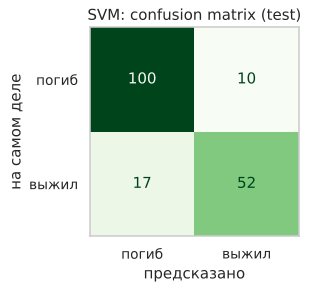

In [28]:
svm = evaluate("SVM", make_pipeline(SVC(random_state=RANDOM_STATE, **svm_params), scale=True))

In [29]:
scale_check = []
for name, model in [("SVM", SVC(random_state=RANDOM_STATE, **svm_params))]:
    for scale in [True, False]:
        r = cross_validate(make_pipeline(model, scale), X_train, y_train, cv=cv_rep, scoring="f1", n_jobs=-1)
        scale_check.append({"модель": name, "масштабирование": "да" if scale else "нет", "CV F1": r["test_score"].mean()})
pd.DataFrame(scale_check)

,модель,масштабирование,CV F1
0,SVM,да,0.771
1,SVM,нет,0.701


**Выводы по SVM.** Подобраны `C = 30`, `gamma = 0.01`: малый `gamma` даёт гладкую, почти линейную границу, а большой `C` позволяет ей точнее подстроиться под данные. Разрыв train / CV минимальный (0.775 / 0.771) — переобучения нет. Без масштабирования SVM с теми же параметрами заметно хуже (CV F1 0.70 против 0.77): расстояние между пассажирами почти полностью определяется `Fare` (разброс в сотни единиц), а пол и класс (0/1 после one-hot) в нём почти не видны. После стандартизации все числовые признаки вносят в расстояние сопоставимый вклад. У SVM нет встроенной feature importance (для RBF-ядра нет весов отдельных признаков), поэтому её важность в разделе 8 оценена только через permutation.

### 6.5. K-Nearest Neighbors

KNN не строит модель: для нового пассажира он находит `k` ближайших пассажиров из train и голосует их классами. «Ближайший» определяется евклидовым расстоянием $\sqrt{\sum_j (x_j - x'_j)^2}$, в котором **каждый признак входит со своим масштабом**. Если `Fare` меняется от 0 до 512, а `Sex_male` — от 0 до 1, то разница в цене билета в 20 фунтов «весит» в 400 раз больше, чем разница в поле. Соседями окажутся люди с похожей ценой билета, независимо от пола и возраста, — то есть модель будет игнорировать самый важный признак. Поэтому для KNN масштабирование обязательно.

In [30]:
knn_best, knn_params, knn_top = tune(KNeighborsClassifier(),
                                     {"n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31], "weights": ["uniform", "distance"]}, scale=True)
print("Лучшие параметры:", knn_params)
knn_top

Лучшие параметры: {'n_neighbors': 31, 'weights': 'distance'}


,n_neighbors,weights,mean_test_score,std_test_score
15,31,distance,0.743,0.040
12,21,uniform,0.742,0.046
13,21,distance,0.741,0.041
6,9,uniform,0.730,0.036
10,15,uniform,0.726,0.046


KNN


,Accuracy,Precision,Recall,F1,"CV F1 (train, 5×5)"
train,0.987,0.996,0.971,0.983,0.74
test,0.816,0.790,0.710,0.748,NaN


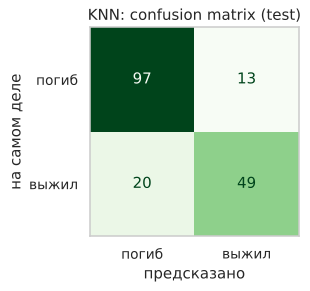

In [31]:
knn = evaluate("KNN", make_pipeline(KNeighborsClassifier(**knn_params), scale=True))

In [32]:
for scale in [True, False]:
    r = cross_validate(make_pipeline(KNeighborsClassifier(**knn_params), scale), X_train, y_train,
                       cv=cv_rep, scoring="f1", n_jobs=-1)
    scale_check.append({"модель": "KNN", "масштабирование": "да" if scale else "нет", "CV F1": r["test_score"].mean()})
pd.DataFrame(scale_check)

,модель,масштабирование,CV F1
0,SVM,да,0.771
1,SVM,нет,0.701
2,KNN,да,0.740
3,KNN,нет,0.611


In [33]:
# какие признаки "видит" KNN без масштабирования: разброс признаков после предобработки
prep_raw = make_preprocessor(scale=False).fit(X_train)
spread = pd.Series(prep_raw.transform(X_train).std(axis=0), index=prep_raw.get_feature_names_out())
print("Стандартное отклонение признаков без масштабирования (вклад в расстояние ~ квадрату):")
print(spread.sort_values(ascending=False).round(2).head(6).to_string())

Стандартное отклонение признаков без масштабирования (вклад в расстояние ~ квадрату):
Fare          48.03
Age           13.02
FamilySize     1.59
SibSp          1.06
Parch          0.84
Pclass_3       0.50


**Выводы по KNN.**
* Эксперимент подтверждает теорию: без масштабирования CV F1 у KNN падает с 0.74 до 0.61. Стандартное отклонение `Fare` ≈ 48, `Age` ≈ 13, а у one-hot признаков — не больше 0.5, то есть расстояние почти целиком определяется ценой билета и возрастом, а пол почти не влияет.
* После стандартизации KNN работает разумно, но уступает деревьям и SVM на CV: у него нет механизма отбора признаков — малополезные признаки (`Embarked`, `Parch`, `SibSp`) участвуют в расстоянии наравне с полом и добавляют шум.
* Подобрано большое `k = 31` с весами по расстоянию: при маленьком `k` модель повторяет шум отдельных соседей, при большом — сглаживает.
* **Train F1 = 0.98 здесь не означает переобучения в обычном смысле.** При `weights="distance"` каждый объект train является сам себе соседом с нулевым расстоянием и бесконечным весом, поэтому на train KNN просто «вспоминает» ответ. Для оценки KNN нужно смотреть только на CV и тест (0.74 и 0.75 — близки).

## 7. Честное сравнение моделей

Все модели обучены на **одном и том же train** (712 пассажиров), с одинаковой предобработкой (масштабирование — только там, где оно нужно алгоритму), гиперпараметры выбраны по CV на train, оценка — на **одном и том же test** (179 пассажиров). CV F1 посчитан на одних и тех же фолдах (5 фолдов × 5 повторов) для всех моделей.

In [34]:
main_models = ["Baseline (most frequent)", "Decision Tree", "Random Forest", "Gradient Boosting", "SVM", "KNN"]
summary = pd.DataFrame(results).T.loc[main_models]
summary["CV F1 (train)"] = [cv_table[m]["CV F1"] for m in main_models]
summary["CV F1 std"] = [cv_table[m]["CV F1 std"] for m in main_models]
summary["Train F1"] = [f1_score(y_train, fitted[m].predict(X_train)) for m in main_models]
summary["F1 > 0.70"] = np.where(summary["F1"] > 0.70, "да", "нет")
summary.index.name = "Модель"
summary.round(3)

,Accuracy,Precision,Recall,F1,CV F1 (train),CV F1 std,Train F1,F1 > 0.70
Модель,,,,,,,,
Baseline (most frequent),0.615,0.000,0.000,0.000,0.000,0.000,0.000,нет
Decision Tree,0.832,0.820,0.725,0.769,0.758,0.050,0.768,да
Random Forest,0.799,0.770,0.681,0.723,0.770,0.043,0.778,да
Gradient Boosting,0.788,0.754,0.667,0.708,0.766,0.045,0.786,да
SVM,0.849,0.839,0.754,0.794,0.771,0.048,0.775,да
KNN,0.816,0.790,0.710,0.748,0.740,0.039,0.983,да


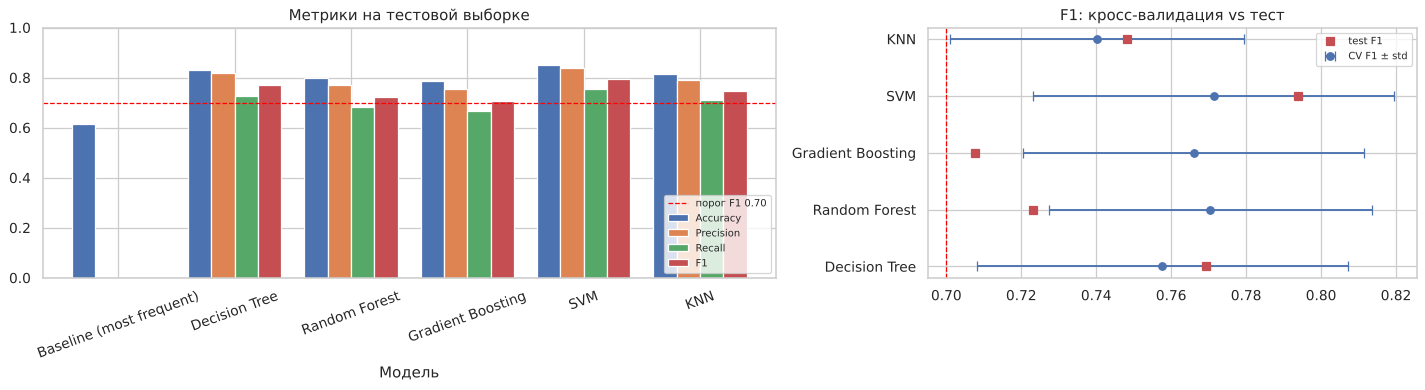

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [3, 2]})
summary[["Accuracy", "Precision", "Recall", "F1"]].plot.bar(ax=axes[0], width=0.8)
axes[0].axhline(0.70, color="red", ls="--", lw=1, label="порог F1 0.70")
axes[0].set_title("Метрики на тестовой выборке")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(loc="lower right", fontsize=8)
m = summary.drop(index="Baseline (most frequent)")
axes[1].errorbar(m["CV F1 (train)"], range(len(m)), xerr=m["CV F1 std"], fmt="o", capsize=4, label="CV F1 ± std")
axes[1].plot(m["F1"], range(len(m)), "s", color="#C44E52", label="test F1")
axes[1].set_yticks(range(len(m)))
axes[1].set_yticklabels(m.index)
axes[1].axvline(0.70, color="red", ls="--", lw=1)
axes[1].set_title("F1: кросс-валидация vs тест")
axes[1].legend(fontsize=8)
plt.tight_layout()

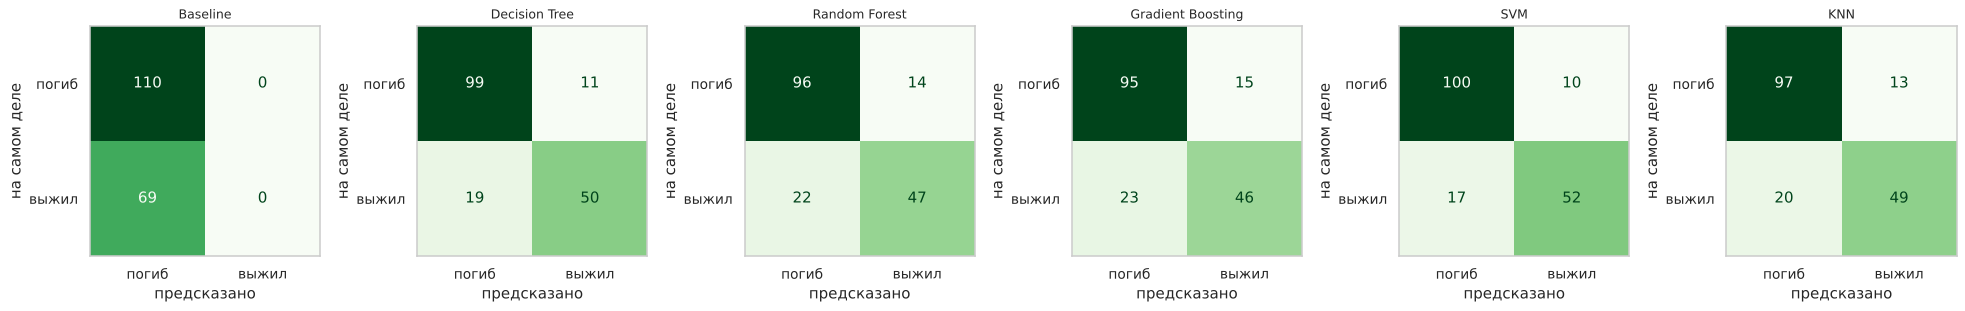

,TN,FP,FN,TP
Baseline (most frequent),110,0,69,0
Decision Tree,99,11,19,50
Random Forest,96,14,22,47
Gradient Boosting,95,15,23,46
SVM,100,10,17,52
KNN,97,13,20,49


In [36]:
fig, axes = plt.subplots(1, 6, figsize=(22, 3.6))
for ax, name in zip(axes, main_models):
    ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred[name]), display_labels=["погиб", "выжил"]).plot(
        ax=ax, cmap="Greens", colorbar=False)
    ax.set_title(name.replace(" (most frequent)", ""), fontsize=10)
    ax.grid(False)
    ax.set_xlabel("предсказано")
    ax.set_ylabel("на самом деле")
plt.tight_layout()
cm_table = pd.DataFrame({n: dict(zip(["TN", "FP", "FN", "TP"], confusion_matrix(y_test, test_pred[n]).ravel()))
                         for n in main_models}).T
cm_table

**Выводы по сравнению.**
* **Порог F1 > 0.70 прошли все пять моделей**; baseline (F1 = 0) — нет. Лучший результат на тесте у **SVM: F1 = 0.794**, Accuracy = 0.849. Он же лучший и по кросс-валидации на train (0.771), поэтому выбран как итоговая модель — выбор сделан **по CV, а не по тесту**.
* **Модели очень близки.** На CV четыре модели (SVM, RF, GB, DT) укладываются в диапазон 0.758–0.771 при стандартном отклонении CV около 0.04–0.05. Честно говоря, по имеющимся данным нельзя уверенно сказать, что одна из них лучше другой. Причина — задача определяется несколькими сильными и простыми правилами (пол, класс, ребёнок ли, размер семьи), которые одинаково хорошо находит почти любая разумная модель; остальное — шум и обстоятельства, которых нет в данных.
* **Тест «скачет» сильнее, чем CV.** На тесте разброс больше (0.708–0.794), и порядок моделей не совпадает с CV: дерево и SVM на тесте лучше своей CV-оценки, бустинг и лес — хуже. В тесте всего 69 выживших, поэтому 3–4 по-разному классифицированных пассажира меняют F1 на 0.03–0.05. Это хорошая иллюстрация, почему нельзя выбирать модель по тесту: «победитель» на тесте во многом определяется случаем.
* **Почему SVM и дерево здесь хороши.** Граница между классами в основном простая — у SVM с маленьким `gamma` она гладкая и почти линейная, а дерево глубины 3 состоит из 7 понятных правил. Простые модели мало подстраиваются под шум, и на маленьком датасете это преимущество.
* **Почему KNN хуже на CV.** Он не умеет отбирать признаки: в расстоянии одинаково участвуют и пол, и малополезные `Embarked`, `Parch`.
* **Какие ошибки делают модели.** У всех моделей FN (пропущенные выжившие, 17–23) больше, чем FP (ложные «выжил», 10–15). Поэтому Recall (0.67–0.75) ниже Precision (0.75–0.84): модели осторожно называют пассажира выжившим и пропускают «нетипичных» выживших — в первую очередь взрослых мужчин (подробнее — в разделе 9).
* **Переобучение.** У подобранных DT, RF, GB и SVM F1 на train, CV и тесте близки — переобучения нет. Высокий train F1 у KNN объясняется весами по расстоянию (см. 6.5), а не реальной подгонкой.

## 8. Важность признаков: сравнение моделей и связь с EDA

Чтобы сравнить модели на одном уровне, **сложим MDI-важности one-hot столбцов** обратно в исходные признаки (`Title_Mr` + `Title_Miss` + … → `Title`) и добавим permutation importance для всех моделей, включая SVM и KNN.

,Decision Tree: MDI,Random Forest: MDI,Gradient Boosting: MDI
Title,0.691,0.301,0.363
Sex,0.000,0.327,0.263
Pclass,0.155,0.094,0.122
FamilySize,0.082,0.047,0.085
HasCabin,0.050,0.066,0.057
Fare,0.008,0.073,0.049
Age,0.013,0.042,0.055
Embarked,0.000,0.018,0.007
SibSp,0.000,0.018,0.000
Parch,0.000,0.013,0.000


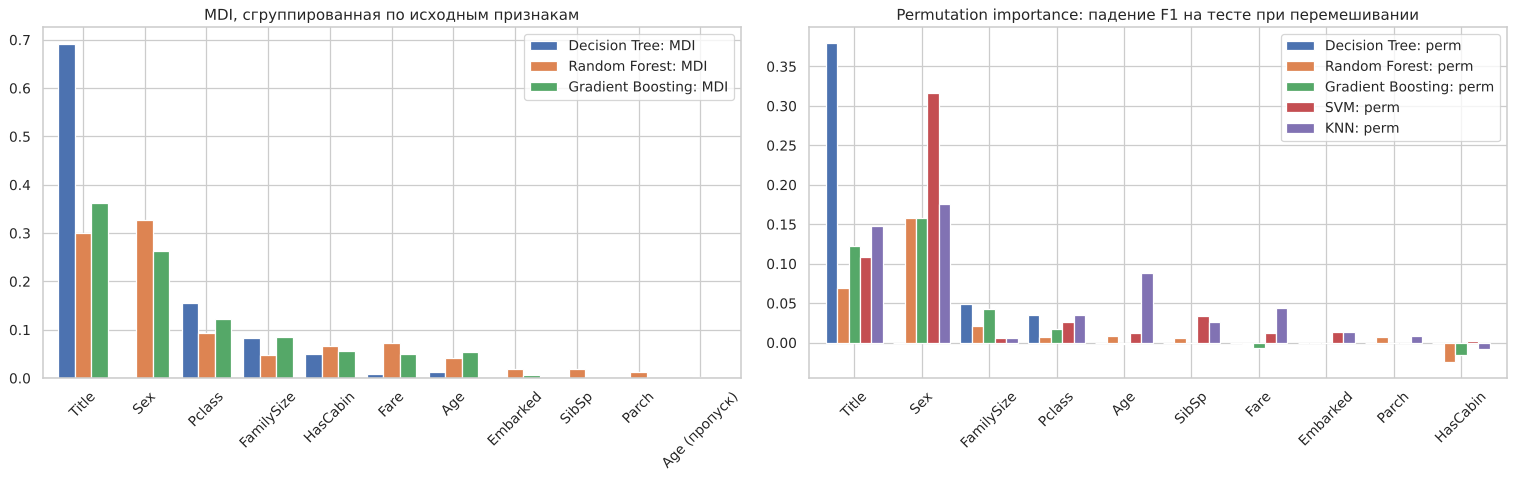

,Decision Tree: perm,Random Forest: perm,Gradient Boosting: perm,SVM: perm,KNN: perm
Title,0.379,0.070,0.123,0.109,0.148
Sex,0.000,0.158,0.158,0.316,0.176
FamilySize,0.049,0.021,0.043,0.005,0.006
Pclass,0.035,0.007,0.018,0.026,0.035
Age,0.000,0.008,-0.001,0.012,0.088
SibSp,0.000,0.005,0.000,0.034,0.026
Fare,0.000,-0.002,-0.007,0.012,0.044
Embarked,0.000,-0.001,-0.001,0.013,0.013
Parch,0.000,0.007,0.000,0.000,0.009
HasCabin,0.000,-0.025,-0.016,0.002,-0.008


In [37]:
def group_mdi(mdi):
    groups = {}
    for col, v in mdi.items():
        base = col
        for f in CAT_FEATURES:
            if col.startswith(f + "_"):
                base = f
        if col.startswith("missingindicator_"):
            base = col.replace("missingindicator_", "") + " (пропуск)"
        groups[base] = groups.get(base, 0) + v
    return pd.Series(groups)


for name in ["SVM", "KNN"]:
    perm = permutation_importance(fitted[name], X_test, y_test, scoring="f1", n_repeats=30,
                                  random_state=RANDOM_STATE, n_jobs=-1)
    importances[name] = (None, pd.Series(perm.importances_mean, index=X_test.columns))

mdi_grouped = pd.DataFrame({f"{n}: MDI": group_mdi(importances[n][0]) for n in ["Decision Tree", "Random Forest", "Gradient Boosting"]}).fillna(0)
perm_all = pd.DataFrame({f"{n}: perm": importances[n][1] for n in ["Decision Tree", "Random Forest", "Gradient Boosting", "SVM", "KNN"]})
order = mdi_grouped.mean(axis=1).sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
mdi_grouped.loc[order].plot.bar(ax=axes[0], width=0.8)
axes[0].set_title("MDI, сгруппированная по исходным признакам")
axes[0].tick_params(axis="x", rotation=45)
perm_order = perm_all.mean(axis=1).sort_values(ascending=False).index
perm_all.loc[perm_order].plot.bar(ax=axes[1], width=0.85)
axes[1].set_title("Permutation importance: падение F1 на тесте при перемешивании")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
display(mdi_grouped.loc[order].round(3))
perm_all.loc[perm_order].round(3)

**Наиболее важные признаки и сравнение моделей.**
* **Пол и обращение (`Sex`, `Title`) — главный сигнал во всех моделях.** У дерева вся эта важность ушла в `Title` (0.69), у леса и бустинга — поделена между `Sex` и `Title` (вместе ≈ 0.63). По permutation перемешивание пола или обращения сильнее всего роняет F1 у всех моделей, у SVM — особенно сильно (на 0.32). Это полностью совпадает с EDA: 74% женщин выжили против 19% мужчин.
* **Второй по важности — класс (`Pclass`)**, затем `FamilySize`, `HasCabin`, `Fare`, `Age`. Это тоже совпадает с EDA: класс сильно влиял на выживание, большие семьи погибали.
* **Где модели расходятся.** Дерево использует 7 признаков, остальные у него с нулевой важностью. Лес распределяет важность по всем признакам, в том числе по шумным (`Embarked`, `SibSp`, `Parch`) — из-за случайного выбора признаков в разбиениях. Бустинг посередине. KNN и SVM, у которых нет встроенной важности, по permutation сильнее других опираются на `Age`, `Fare` и `SibSp` — из-за того, что эти признаки после масштабирования участвуют в расстоянии наравне с остальными.
* **Расхождения с EDA:**
  * `Embarked` в EDA показывал заметную разницу (55% выживших в Шербуре), но для моделей почти бесполезен. Это подтверждает гипотезу из EDA: эффект порта — это эффект класса (в Шербуре садилось больше пассажиров 1-го класса). Когда модель уже знает класс, порт ничего не добавляет.
  * `HasCabin` в EDA был сильным (67% против 30%), у леса и бустинга по MDI заметен, но по permutation на тесте даже отрицателен. Каюта известна в основном у 1-го класса, поэтому признак во многом дублирует `Pclass` и `Fare`.
  * У `Age` в EDA сильная связь была только для детей; модели учитывают её через `Title = Master`, поэтому сам возраст получает немного.
* **MDI против permutation.** MDI считается по train и отражает, как часто признак использовался в разбиениях; permutation — насколько признак реально нужен для качества на новых данных. Расхождения (у `Fare`, `HasCabin`) показывают, что часть «важности» по MDI — подгонка под train или дублирование других признаков.

**Можно ли утверждать, что важный признак — причина выживания? Нет.**
1. Важность показывает, насколько **модель** опирается на признак при предсказании, а не как устроен реальный мир. Это мера ассоциации, а не причинности.
2. Данные наблюдательные, и у признаков есть общие причины. Например, высокий `Fare` сам по себе не спасал: дорогой билет означал 1-й класс, каюту на верхних палубах ближе к шлюпкам, более раннее оповещение. Модель видит цену, а причина — расположение каюты и порядок эвакуации.
3. Коррелированные признаки подменяют друг друга: у дерева важность `Sex` равна 0, хотя пол — пожалуй, самый «причинный» признак здесь (правило «женщины и дети первыми»). Просто модель взяла почти эквивалентный `Title_Mr`. Если бы важность означала причину, пришлось бы заключить, что пол не влиял, а обращение влияло, — что абсурдно.
4. Даже для пола модель отражает **правило поведения людей в ту ночь** (кого сажали в шлюпки), а не биологическое свойство. В другой катастрофе с другими правилами эвакуации зависимость была бы другой.

Для причинных выводов нужен контролируемый эксперимент или специальные методы причинного вывода с явными предположениями.

## 9. Анализ ошибок лучшей модели

In [38]:
candidates = summary.drop(index="Baseline (most frequent)")
best_name = candidates["CV F1 (train)"].idxmax()  # выбираем по кросс-валидации на train, а не по тесту
print("Лучшая модель по CV F1 на train:", best_name)
print(summary.loc[best_name, ["Accuracy", "Precision", "Recall", "F1"]].round(3).to_string())

err = X_test.copy()
err["Name"] = df.loc[X_test.index, "Name"]
err["true"] = y_test
err["pred"] = test_pred[best_name]
err["тип"] = np.select([(err.true == 1) & (err.pred == 1), (err.true == 0) & (err.pred == 0),
                        (err.true == 0) & (err.pred == 1)], ["TP", "TN", "FP"], "FN")
err["ошибка"] = err["тип"].isin(["FP", "FN"])
tn, fp, fn, tp = confusion_matrix(y_test, err["pred"]).ravel()
print(f"\nTN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Из {y_test.sum()} выживших модель пропустила {fn} ({fn / y_test.sum():.0%}); "
      f"из {(y_test == 0).sum()} погибших ошибочно назвала выжившими {fp} ({fp / (y_test == 0).sum():.0%})")

Лучшая модель по CV F1 на train: SVM
Accuracy     0.849
Precision    0.839
Recall       0.754
F1           0.794

TN=100, FP=10, FN=17, TP=52
Из 69 выживших модель пропустила 17 (25%); из 110 погибших ошибочно назвала выжившими 10 (9%)


In [39]:
err["группа"] = err["Sex"].map({"male": "муж", "female": "жен"}) + ", " + err["Pclass"].astype(str) + " кл."
grp = err.groupby("группа").agg(
    n=("true", "size"), выжило=("true", "mean"), предсказано_выжило=("pred", "mean"),
    ошибок=("ошибка", "sum"), доля_ошибок=("ошибка", "mean"),
    FP=("тип", lambda s: (s == "FP").sum()), FN=("тип", lambda s: (s == "FN").sum()))
display(grp.round(2))

err["возраст"] = pd.cut(err["Age"], [0, 12, 18, 35, 60, 100], labels=["0–12", "13–18", "19–35", "36–60", "60+"])
err["возраст"] = err["возраст"].cat.add_categories("неизвестен").fillna("неизвестен")
by_title = err.groupby("Title").agg(n=("true", "size"), доля_ошибок=("ошибка", "mean"),
                                     FP=("тип", lambda s: (s == "FP").sum()), FN=("тип", lambda s: (s == "FN").sum()))
by_age = err.groupby("возраст", observed=False).agg(n=("true", "size"), доля_ошибок=("ошибка", "mean"),
                                                     FP=("тип", lambda s: (s == "FP").sum()), FN=("тип", lambda s: (s == "FN").sum()))
display(by_title.round(2))
by_age.round(2)

,n,выжило,предсказано_выжило,ошибок,доля_ошибок,FP,FN
группа,,,,,,,
"жен, 1 кл.",15,0.93,1.00,1,0.07,1,0
"жен, 2 кл.",18,0.94,1.00,1,0.06,1,0
"жен, 3 кл.",28,0.50,0.79,8,0.29,8,0
"муж, 1 кл.",30,0.37,0.07,9,0.30,0,9
"муж, 2 кл.",16,0.19,0.06,2,0.12,0,2
"муж, 3 кл.",72,0.14,0.06,6,0.08,0,6


,n,доля_ошибок,FP,FN
Title,,,,
Master,9,0.00,0,0
Miss,41,0.17,7,0
Mr,105,0.16,0,17
Mrs,19,0.16,3,0
Rare,5,0.00,0,0


,n,доля_ошибок,FP,FN
возраст,,,,
0–12,14,0.07,1,0
13–18,17,0.00,0,0
19–35,74,0.20,4,11
36–60,28,0.11,1,2
60+,6,0.17,0,1
неизвестен,40,0.18,4,3


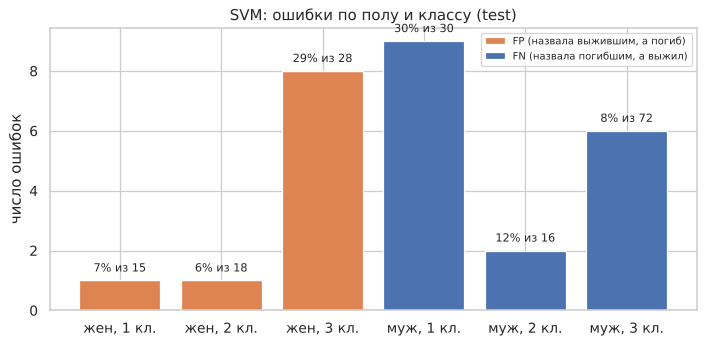

In [40]:
fig, ax = plt.subplots(figsize=(8, 4))
g = grp.sort_index()
ax.bar(g.index, g["FP"], label="FP (назвала выжившим, а погиб)", color="#DD8452")
ax.bar(g.index, g["FN"], bottom=g["FP"], label="FN (назвала погибшим, а выжил)", color="#4C72B0")
for i, (n, e) in enumerate(zip(g["n"], g["доля_ошибок"])):
    ax.text(i, g["FP"].iloc[i] + g["FN"].iloc[i] + 0.3, f"{e:.0%} из {n}", ha="center", fontsize=9)
ax.set_title(f"{best_name}: ошибки по полу и классу (test)")
ax.set_ylabel("число ошибок")
ax.legend(fontsize=8)
plt.tight_layout()

In [41]:
show_cols = ["Name", "Sex", "Age", "Pclass", "Title", "SibSp", "Parch", "Fare", "Embarked", "HasCabin", "true", "pred", "тип"]
proba_model = fitted[best_name]
if hasattr(proba_model, "predict_proba"):
    err["P(выжил)"] = proba_model.predict_proba(X_test)[:, 1]
    show_cols.append("P(выжил)")
elif hasattr(proba_model, "decision_function"):
    err["decision"] = proba_model.decision_function(X_test)
    show_cols.append("decision")
mistakes = err[err["ошибка"]].sort_values("тип")
mistakes[show_cols]

,Name,Sex,Age,Pclass,Title,SibSp,Parch,Fare,Embarked,HasCabin,true,pred,тип,decision
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,3,Mr,0,0,7.225,C,0,1,0,FN,-0.947
570,"Harris, Mr. George",male,62.0,2,Mr,0,0,10.500,S,0,1,0,FN,-1.020
55,"Woolner, Mr. Hugh",male,NaN,1,Mr,0,0,35.500,S,1,1,0,FN,-0.997
146,"Andersson, Mr. August Edvard (""Wennerstrom"")",male,27.0,3,Mr,0,0,7.796,S,0,1,0,FN,-1.026
690,"Dick, Mr. Albert Adrian",male,31.0,1,Mr,1,0,57.000,S,1,1,0,FN,-0.942
607,"Daniel, Mr. Robert Williams",male,27.0,1,Mr,0,0,30.500,S,0,1,0,FN,-1.035
447,"Seward, Mr. Frederic Kimber",male,34.0,1,Mr,0,0,26.550,S,0,1,0,FN,-1.041
271,"Tornquist, Mr. William Henry",male,25.0,3,Mr,0,0,0.000,S,0,1,0,FN,-1.027
701,"Silverthorne, Mr. Spencer Victor",male,35.0,1,Mr,0,0,26.288,S,1,1,0,FN,-0.976
444,"Johannesen-Bratthammer, Mr. Bernt",male,NaN,3,Mr,0,0,8.113,S,0,1,0,FN,-1.095


**Выводы по ошибкам SVM.**
* **Чаще встречаются FN** — 17 пропущенных выживших (25% всех выживших) против 10 FP (9% погибших). Модель «осторожна»: называет пассажира выжившим только при сильных основаниях.
* **Ошибки чётко делятся по полу:**
  * **все 17 FN — взрослые мужчины (`Mr`)**, которые выжили. Модель практически всем взрослым мужчинам предсказывает гибель: среди мужчин теста предсказано выжившими лишь 6%, а реально выжило 14–37% в зависимости от класса;
  * **все 10 FP — женщины**, которые погибли, из них 8 — из 3-го класса. Женщинам модель почти всегда предсказывает выживание (в 1–2 классе это верно в 94–97% случаев, в 3-м — лишь в 50%).
* **Сильнее всего модель ошибается в двух группах** — мужчины 1-го класса (30% ошибок, 9 FN) и женщины 3-го класса (29% ошибок, 8 FP). Это ровно те группы, где в EDA выживание было ближе всего к 50/50: мужчины 1-го класса выжили в 37% случаев, женщины 3-го — в 50%. Здесь пол и класс «тянут» в разные стороны, а других признаков, которые бы разделили этих людей, в данных почти нет.
* Дети (`Master`, возраст до 12) и пассажиры с редкими обращениями предсказываются почти без ошибок.

**Разбор нескольких ошибок:**
* **Bishop, Mr. Dickinson H (FN)** — мужчина 25 лет, 1-й класс, с каютой и дорогим билетом (91 фунт), путешествовал с женой. По всем признакам — «лучший» случай для мужчины, и решающая функция у него близка к границе (−0.74). Но правило «взрослый мужчина → погиб» перевесило. Выжили многие мужчины 1-го класса, оказавшиеся рядом со шлюпками в нужный момент, — этого в данных нет.
* **Tornquist, Mr. William Henry (FN)** — мужчина 3-го класса с ценой билета 0. По данным это типичный погибший. Нулевая цена у нескольких пассажиров означает служебный проезд (сотрудники судоходной компании); его выживание объясняется обстоятельствами, которых модель знать не может. Такие ошибки неустранимы на этих признаках.
* **Allison, Miss. Helen Loraine (FP)** — девочка 2 лет из 1-го класса, каюта, дорогой билет. По всем признакам модель уверена в выживании (+1.23) — и в общем случае это верно: почти все дети и женщины 1-го класса выжили. Известно, что она погибла вместе с матерью, которая не села в шлюпку, разыскивая на судне сына. Это исключение, которое невозможно предсказать по этим данным.
* **O'Sullivan, Miss. Bridget Mary и Canavan, Miss. Mary (FP)** — молодые женщины 3-го класса, путешествовали одни, сели в Квинстауне. Модель следует общему правилу «женщина → выжила», но среди женщин 3-го класса выжила лишь половина. Каюты 3-го класса находились в нижней части судна и дальше от шлюпок — это не отражено в признаках напрямую.

**Общий вывод:** модель фактически выучила историческое правило «женщины и дети — первыми» с поправкой на класс и размер семьи. Она ошибается на **исключениях из этого правила**, у которых в данных нет признаков, отличающих их от типичных пассажиров своей группы.

### 9.1. Не связано ли качество с «запоминанием» конкретных пассажиров?

Проверим три вещи.
1. **В модели нет идентификаторов.** `PassengerId`, `Name`, `Ticket`, `Cabin` удалены; из имени взято только обращение (5 значений), из каюты — только флаг наличия.
2. **Что было бы, если оставить идентификаторы.** Добавим `PassengerId`, а также `Name`, `Ticket` и `Cabin` как категории (one-hot) и обучим дерево без ограничений и лучшую модель.
3. **Разрыв train / test у итоговых моделей** — нет ли признаков запоминания (см. таблицу в разделе 7).

In [42]:
X_id = data[FEATURES + ["PassengerId", "Name", "Ticket", "Cabin"]]
Xid_train, Xid_test = X_id.loc[X_train.index], X_id.loc[X_test.index]


def make_id_pipeline(model, scale):
    base = make_preprocessor(scale)
    return Pipeline([("prep", ColumnTransformer(
        base.transformers + [("id_num", "passthrough", ["PassengerId"]),
                             ("id_cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="нет")),
                                                  ("onehot", OneHotEncoder(handle_unknown="ignore"))]), ["Name", "Ticket", "Cabin"])],
        verbose_feature_names_out=False)),
                     ("model", model)])


id_check = []
best_model_obj = fitted[best_name].named_steps["model"]
best_scaled = best_name in ("SVM", "KNN")
for label, model, scale in [("Decision Tree (без ограничений)", DecisionTreeClassifier(random_state=RANDOM_STATE), False),
                            (best_name, best_model_obj, best_scaled)]:
    for use_ids in [False, True]:
        pipe = make_id_pipeline(model, scale) if use_ids else make_pipeline(model, scale)
        Xa, Xb = (Xid_train, Xid_test) if use_ids else (X_train, X_test)
        cvs = cross_validate(pipe, Xa, y_train, cv=cv_rep, scoring="f1", n_jobs=-1)["test_score"].mean()
        pipe.fit(Xa, y_train)
        id_check.append({"модель": label, "идентификаторы": "да" if use_ids else "нет",
                         "train F1": f1_score(y_train, pipe.predict(Xa)), "CV F1": cvs,
                         "test F1": f1_score(y_test, pipe.predict(Xb))})
id_check = pd.DataFrame(id_check)
id_check.round(3)

,модель,идентификаторы,train F1,CV F1,test F1
0,Decision Tree (без ограничений),нет,0.983,0.717,0.714
1,Decision Tree (без ограничений),да,1.000,0.761,0.711
2,SVM,нет,0.775,0.771,0.794
3,SVM,да,1.000,0.491,0.508


In [43]:
# какие признаки использует дерево без ограничений, если ему дать идентификаторы
pipe = make_id_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), False).fit(Xid_train, y_train)
imp_id = pd.Series(pipe.named_steps["model"].feature_importances_, index=pipe.named_steps["prep"].get_feature_names_out())
imp_id = imp_id[imp_id > 0].sort_values(ascending=False)
print("Важность PassengerId:", round(imp_id.get("PassengerId", 0), 3))
print("Суммарная важность one-hot столбцов Name/Ticket/Cabin:",
      round(imp_id[imp_id.index.str.startswith(("Name_", "Ticket_", "Cabin_"))].sum(), 3))
imp_id.head(10).round(3)

Важность PassengerId: 0.032
Суммарная важность one-hot столбцов Name/Ticket/Cabin: 0.346


Title_Mr       0.309
Fare           0.089
Pclass_3       0.076
FamilySize     0.051
PassengerId    0.032
Age            0.030
Title_Rare     0.030
Cabin_нет      0.025
HasCabin       0.020
Ticket_1601    0.019
dtype: float64

**Выводы по проверке на «запоминание».**
* **С идентификаторами обе модели запоминают обучающую выборку**: train F1 = 1.00. Но на новых пассажирах это не помогает:
  * SVM с идентификаторами резко ухудшается (CV F1 0.49, тест 0.51 вместо 0.77 и 0.79). One-hot по `Name`, `Ticket`, `Cabin` добавляет сотни столбцов, каждый из которых равен 1 ровно у одного-двух пассажиров. Расстояния в ядре начинают определяться этими «уникальными метками», и модель фактически запоминает людей вместо того, чтобы обобщать;
  * дерево без ограничений отдаёт идентификаторам заметную долю важности: `PassengerId` — 0.03, а one-hot столбцам `Name`/`Ticket`/`Cabin` в сумме — 0.35, то есть больше трети всех разбиений. Это, например, отдельные номера билетов вроде `Ticket_1601` — случайные совпадения в train, а не закономерности. Тест F1 от этого не растёт (0.711 против 0.714).
* **Итоговые модели обучены без идентификаторов**, и у них нет разрыва между train и тестом (у SVM — 0.775 и 0.794). Значит, высокое качество **не связано с запоминанием конкретных пассажиров**: модель опирается на общие признаки (пол, класс, возраст, семья).
* **Нежелательная информация.** В наших признаках нет данных, известных только после катастрофы (`Boat`, `Body`). Все признаки известны на момент посадки на судно. `Title` и `HasCabin` извлечены из текстовых полей без использования целевой переменной.
* Отдельно стоит помнить, что основной вклад дают `Sex` и `Title` — модель использует пол как главный фактор. Для исторического анализа это корректно (так шла эвакуация), но такую модель нельзя переносить на решения о реальных людях: она воспроизводит закономерность конкретного события, а не что-то «правильное».

## 10. Итоговая модель

Для предсказаний на скрытой тестовой выборке переобучаем выбранную модель с теми же гиперпараметрами **на всех 891 пассажирах** (все решения уже приняты по CV, тест для выбора больше не нужен). Функция `predict_survival` принимает таблицу в исходном формате Kaggle (с колонками `Name`, `Cabin`, `SibSp`, …) и сама строит признаки.

In [44]:
import joblib
from sklearn.base import clone

final_model = clone(fitted[best_name]).fit(X, y)
joblib.dump({"model": final_model, "features": FEATURES}, "final_model_lab02.joblib")


def predict_survival(raw_table, path="final_model_lab02.joblib"):
    bundle = joblib.load(path)
    return bundle["model"].predict(add_features(raw_table)[bundle["features"]])


print("Итоговая модель:", best_name, "обучена на", len(X), "пассажирах")
print("Проверка на первых 5 пассажирах файла:", predict_survival(df.head()), " истинные:", df[TARGET].head().tolist())

Итоговая модель: SVM обучена на 891 пассажирах
Проверка на первых 5 пассажирах файла: [0 1 1 1 0]  истинные: [0, 1, 1, 1, 0]


## Итоги

| Модель | Accuracy | Precision | Recall | F1 (test) | CV F1 (train) |
|---|---|---|---|---|---|
| Baseline (most frequent) | 0.615 | 0.000 | 0.000 | 0.000 | 0.000 |
| Decision Tree | 0.832 | 0.820 | 0.725 | 0.769 | 0.758 |
| Random Forest | 0.799 | 0.770 | 0.681 | 0.723 | 0.770 |
| Gradient Boosting | 0.788 | 0.754 | 0.667 | 0.708 | 0.766 |
| **SVM** | **0.849** | **0.839** | **0.754** | **0.794** | **0.771** |
| KNN | 0.816 | 0.790 | 0.710 | 0.748 | 0.740 |

* Данные: 891 пассажир, 38% выживших. Удалены идентификаторы (`PassengerId`, `Name`, `Ticket`, `Cabin`); из имени и каюты извлечены `Title` и `HasCabin`, добавлен `FamilySize`. Пропуски и категории обработаны внутри `Pipeline`, только по train.
* Разбиение 80/20 со стратификацией, `random_state=42`; гиперпараметры подобраны кросс-валидацией на train.
* Все пять моделей прошли порог F1 > 0.70. Итоговая модель — **SVM** (лучшая по CV, F1 на тесте 0.794). Масштабирование критично для SVM и KNN и не нужно деревьям.
* Главные признаки — пол/обращение и класс, что совпадает с EDA и историческим правилом «женщины и дети первыми». Важность признаков не говорит о причинности.
* Основные ошибки — выжившие взрослые мужчины (FN) и погибшие женщины 3-го класса (FP). Высокое качество не связано с запоминанием пассажиров.